### EN3160 Assignment 2 on Fitting and Alignment

#### Index Number: 230724E
#### Name: Wijesekara WAGS

---

##### Github Link:  https://github.com/SathsaraGeeth/_vision_a02_.git

## 1. Blob Detection


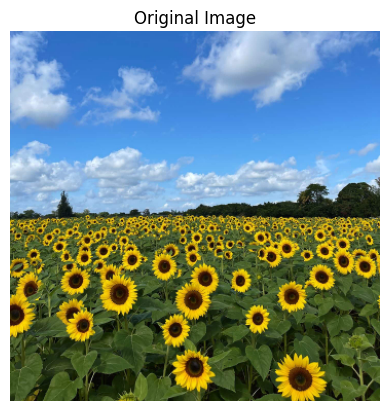

Blob 1: center=(282, 338), radius=10.14 pixels
Blob 2: center=(179, 327), radius=9.00 pixels
Blob 3: center=(106, 255), radius=7.85 pixels
Blob 4: center=(178, 261), radius=7.85 pixels
Blob 5: center=(189, 240), radius=6.71 pixels
Blob 6: center=(161, 290), radius=6.71 pixels
Blob 7: center=(63, 243), radius=6.71 pixels
Blob 8: center=(274, 258), radius=6.71 pixels
Blob 9: center=(303, 239), radius=5.56 pixels
Blob 10: center=(241, 279), radius=5.56 pixels


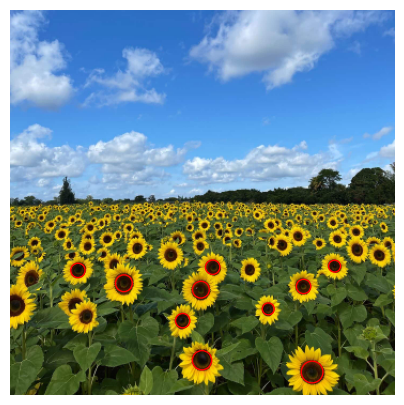

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

im = cv.imread("the_berry_farms_sunflower_field.jpeg", cv.IMREAD_REDUCED_COLOR_4)

plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")
plt.show()

# ker_sz shall be an odd positive integer
def NormalizedLapOfGauss2D(sigma, ker_sz):
    x = np.arange(-(ker_sz // 2), ker_sz // 2 + 1)
    y = np.arange(-(ker_sz // 2), ker_sz // 2 + 1)
    X, Y = np.meshgrid(x, y)
    r2 = X**2 + Y**2
    kernel = (r2 - 2 * sigma**2) / (2 * np.pi * sigma**6)
    kernel *= np.exp(-r2 / (2 * sigma**2))
    kernel *= sigma**2
    kernel -= kernel.mean()

    return kernel

def BlobDetector(image, num_blobs=25, threshold_rel=0.03, sigma_min=1.5, sigma_max=25, num_scales=30):
                 
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY).astype(np.float64)

    sigmas = np.linspace(sigma_min, sigma_max, num_scales)
    responses = []

    # Convolve image with scale-normalized Laplacian at several scales
    for sigma in sigmas:
        ker_sz = 2 * int(np.ceil(3 * sigma)) + 1
        kernel = NormalizedLapOfGauss2D(sigma, ker_sz)
        response = cv.filter2D(gray, cv.CV_64F, kernel, borderType=cv.BORDER_REFLECT101)
        responses.append(response ** 2)

    # Find maxima of squared Laplacian response in scale-space
    scale_space = np.stack(responses, axis=0)
    local_max = maximum_filter(scale_space, size=(3, 3, 3))
    threshold = threshold_rel * scale_space.max()
    maxima = (scale_space == local_max) & (scale_space > threshold)

    maxima[0] = False
    maxima[-1] = False

    scale_idx, ys, xs = np.where(maxima)

    height, width = gray.shape
    candidates = []
    for s, y, x in zip(scale_idx, ys, xs):
        radius = np.sqrt(2) * sigmas[s]

        if x - radius < 0 or x + radius >= width:
            continue
        if y - radius < 0 or y + radius >= height:
            continue

        score = float(scale_space[s, y, x])
        candidates.append((int(x), int(y), float(radius), score))

    candidates.sort(key=lambda blob: blob[3], reverse=True)
    detected = []
    for x, y, radius, score in candidates:
        overlaps = any((x - px)**2 + (y - py)**2 < max(radius, pr)**2 for px, py, pr in detected)
        if not overlaps:
            detected.append((x, y, radius))

    return detected[:num_blobs]

# Limit to 10 largest blobs out of strongest 25 detections
blobs = sorted(BlobDetector(im, num_blobs=25), key=lambda blob: blob[2], reverse=True)[:10]

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))

for index, (x, y, radius) in enumerate(blobs, start=1):
    ax.add_patch(plt.Circle((x, y), radius, color='red', fill=False))
    print(f"Blob {index}: center=({x}, {y}), radius={radius:.2f} pixels")


ax.axis("off")
plt.show()

The image was first converted to grayscale. It was then convolved with the scale-normalized Laplacian of Gaussian at 30 scales in the range $1.5 \leq \sigma \leq 25$. The blobs were found by looking for maxima of the squared Laplacian response in space and scale. Responses below 3% of the maximum response were ignored, together with detections touching the image boundary. Overlapping detections were removed, and the 10 largest circles from the 25 strongest detections were drawn. The radius of each blob was found using $r=\sqrt{2}\sigma$.

The detected circle parameters $(x,y,r)$ are printed by the code.

## 3. Homography

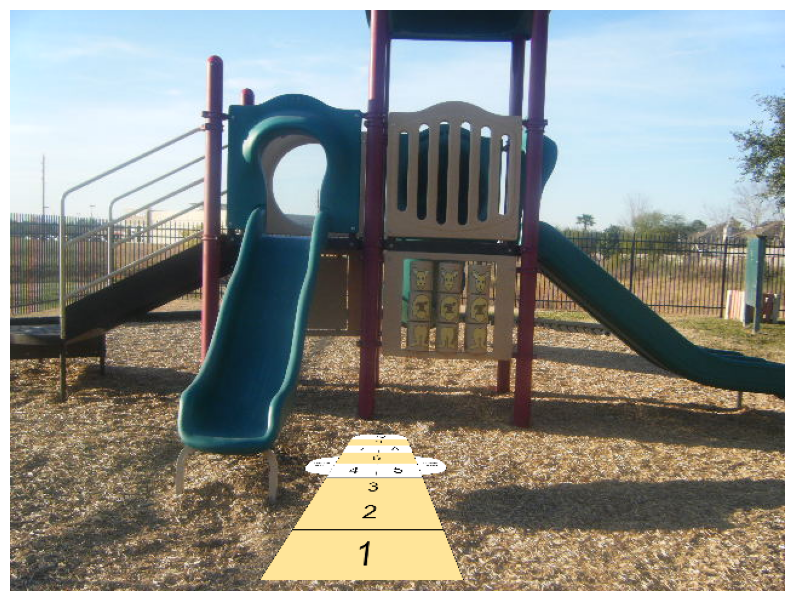

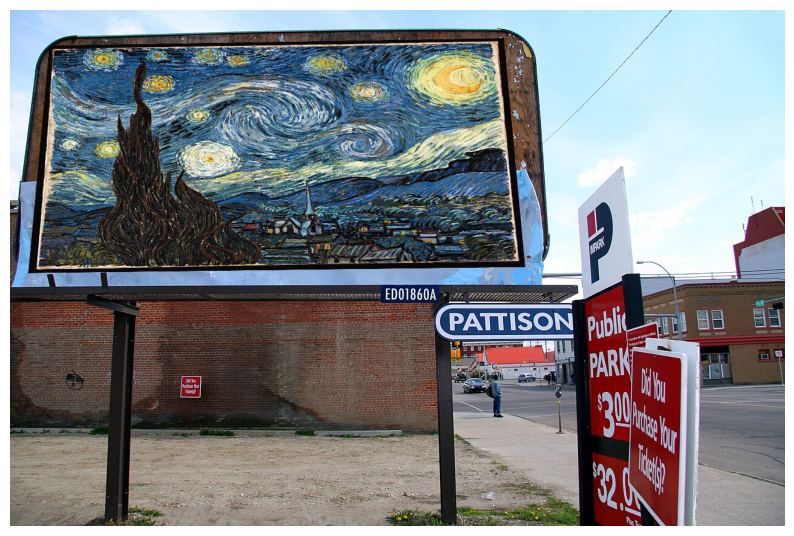

In [2]:
# load images
def add_flag(destination_path, source_path, destination_points):
    destination = cv.cvtColor(cv.imread(destination_path), cv.COLOR_BGR2RGB)
    source_file = cv.imread(source_path, cv.IMREAD_UNCHANGED)
    if source_file.shape[2] == 4:
        source = cv.cvtColor(source_file, cv.COLOR_BGRA2RGB)
        source_mask = source_file[:, :, 3]
    else:
        source = cv.cvtColor(source_file, cv.COLOR_BGR2RGB)
        source_mask = np.full(source.shape[:2], 255, dtype=np.uint8)

    # select 4 points from the pair
    destination_points = np.float32(destination_points)

    height, width = source.shape[:2]
    source_points = np.float32([
        [0, 0],
        [width - 1, 0],
        [width - 1, height - 1],
        [0, height - 1]
    ])

    # compute the homography
    H, _ = cv.findHomography(source_points, destination_points)

    # transform the source image to destination images coordinates
    destination_height, destination_width = destination.shape[:2]
    warped_source = cv.warpPerspective(source, H, (destination_width, destination_height))

    # create a mask that identify the destination image covered by the source image
    mask = cv.warpPerspective(source_mask, H, (destination_width, destination_height))

    # blend them
    alpha = mask.astype(np.float32)[..., None] / 255.0
    result = destination * (1 - alpha) + warped_source * alpha
    result = result.astype(np.uint8)

    plt.figure(figsize=(10, 8))
    plt.imshow(result)
    plt.axis("off")
    plt.show()

    return result

pair_1 = add_flag(
    "homography_images/empty_playground.jpg",
    "homography_images/hopscotch_cropped.png",
    [[270, 350], [340, 350], [430, 470], [150, 470]]
)

pair_2 = add_flag(
    "homography_images/empty_billboard.jpg",
    "homography_images/starry_night.jpg",
    [[65, 60], [815, 48], [850, 425], [30, 435]]
)

For each pair, four points were selected on the flat surface of the destination image. These points were matched with the four corners of the source image to calculate the homography. The source image and its mask were then warped to the destination coordinates and blended with the destination image.

For the first pair, a hopscotch pattern was placed on the ground of an empty playground. This was chosen because the pattern belongs naturally in a playground, while the sloping ground makes the perspective change easy to see. For the second pair, The Starry Night art was placed on an empty billboard.

## 4. PCB Image Alignment

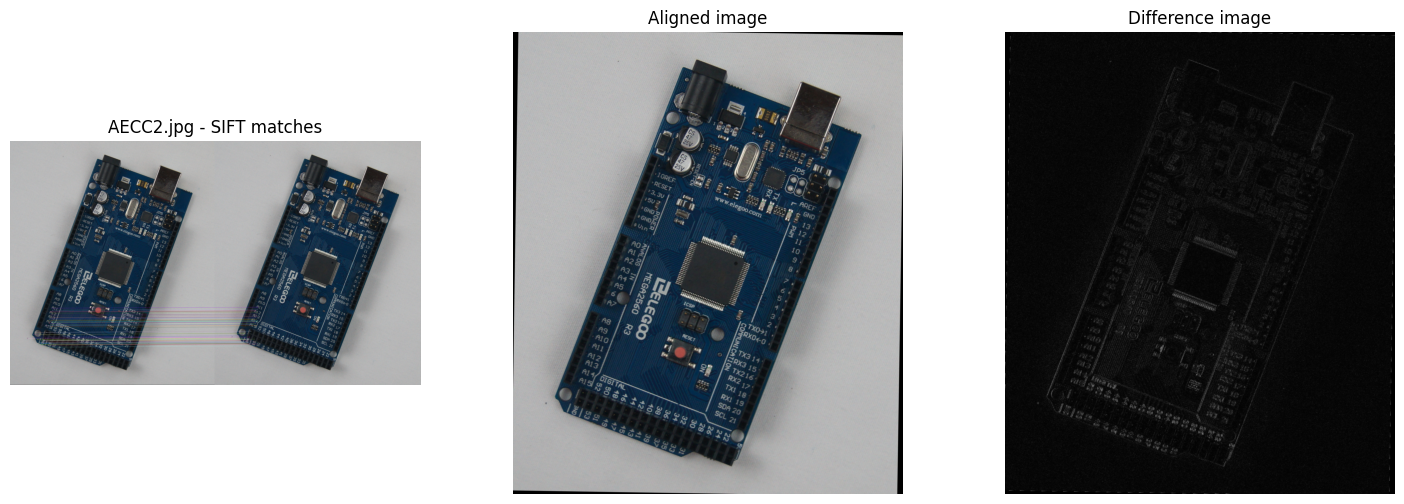

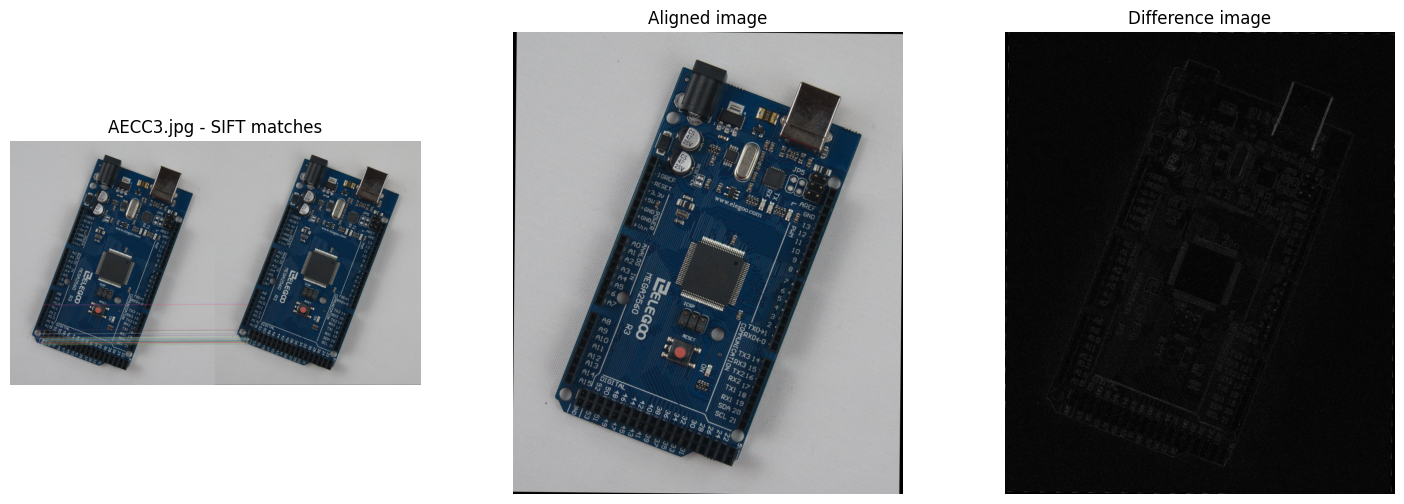

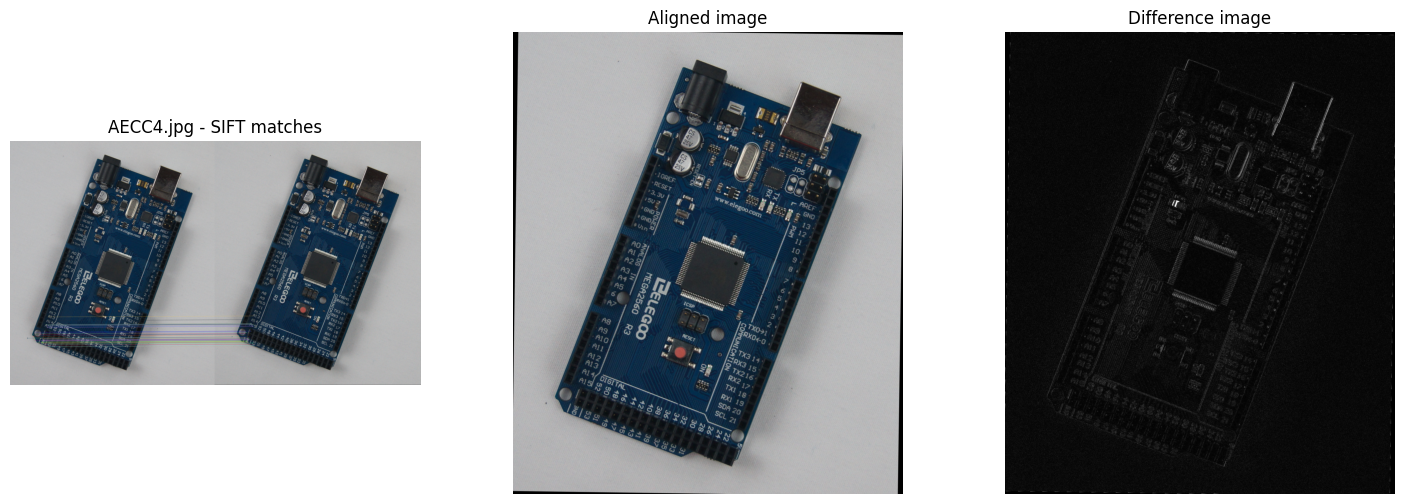

In [3]:
# Load the template
template = cv.imread("AECC1.jpg")
template_gray = cv.cvtColor(template, cv.COLOR_BGR2GRAY)

# Find SIFT features in the template
sift = cv.SIFT_create()
kp1, des1 = sift.detectAndCompute(template_gray, None)
bf = cv.BFMatcher()

def align_pcb(filename):
    image = cv.imread(filename)
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)

    # Find and match SIFT features
    kp2, des2 = sift.detectAndCompute(gray, None)
    matches = bf.knnMatch(des2, des1, k=2)
    good = [m for m, n in matches if m.distance < 0.75 * n.distance]

    # Find the homography using RANSAC
    src = np.float32([kp2[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)
    dst = np.float32([kp1[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)
    H, mask = cv.findHomography(src, dst, cv.RANSAC, 5.0)

    inliers = [m for m, keep in zip(good, mask.ravel()) if keep]
    match_image = cv.drawMatches(image, kp2, template, kp1, inliers[:60], None, flags=2)

    # Align the image and find the difference
    h, w = template.shape[:2]
    aligned = cv.warpPerspective(image, H, (w, h))
    valid = cv.warpPerspective(np.ones(gray.shape, np.uint8), H, (w, h))
    difference = cv.cvtColor(cv.absdiff(template, aligned), cv.COLOR_BGR2GRAY)
    difference[valid == 0] = 0

    return match_image, aligned, difference

images = ["AECC2.jpg", "AECC3.jpg", "AECC4.jpg"]

for filename in images:
    matches, aligned, difference = align_pcb(filename)

    plt.figure(figsize=(18, 6))
    plt.subplot(1, 3, 1)
    plt.imshow(cv.cvtColor(matches, cv.COLOR_BGR2RGB))
    plt.title(filename + " - SIFT matches")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(cv.cvtColor(aligned, cv.COLOR_BGR2RGB))
    plt.title("Aligned image")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(difference, cmap="gray", vmin=0, vmax=80)
    plt.title("Difference image")
    plt.axis("off")

    plt.show()

`AECC1.jpg` was used as the template. SIFT keypoints and descriptors were found in the template and in each of the other AECC images. The descriptors were matched using a brute-force matcher. The nearest match was kept when its distance was less than 0.75 times the distance of the second-nearest match. A homography was then fitted from these matches using RANSAC.

Each PCB image was warped to the template coordinates using the homography. The difference image was calculated using the absolute pixel difference between the aligned image and the template. The same steps were used for `AECC2.jpg`, `AECC3.jpg`, and `AECC4.jpg`. Bright areas in the difference images show places that do not agree with the template.

### (e) Reason for high differences

The USB port, capacitors, and reset button are raised above the flat PCB. When the viewing angle changes, these parts move differently from the board surface because of parallax. A single homography can align the flat board, but it cannot fully align components at different heights. Changes in lighting and shadows also make these areas brighter in the difference image.